In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, cross_validate
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor 
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
pd.set_option('display.max_columns', None)

In [2]:
df5 = pd.read_csv('House_Rent_Dataset.csv')
df_train = df5.copy()
df5

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner
...,...,...,...,...,...,...,...,...,...,...,...,...
4741,2022-05-18,2,15000,1000,3 out of 5,Carpet Area,Bandam Kommu,Hyderabad,Semi-Furnished,Bachelors/Family,2,Contact Owner
4742,2022-05-15,3,29000,2000,1 out of 4,Super Area,"Manikonda, Hyderabad",Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Owner
4743,2022-07-10,3,35000,1750,3 out of 5,Carpet Area,"Himayath Nagar, NH 7",Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Agent
4744,2022-07-06,3,45000,1500,23 out of 34,Carpet Area,Gachibowli,Hyderabad,Semi-Furnished,Family,2,Contact Agent


In [3]:
df5.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


In [4]:
df5.duplicated().sum()

np.int64(0)

In [5]:
df5.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.746000e+03,4746.000000,4746.000000
mean,2.083860,3.499345e+04,967.490729,1.965866
std,0.832256,7.810641e+04,634.202328,0.884532
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


In [6]:
def clean(data, cols):
    for coli in cols:
        data[coli] = pd.to_numeric(data[coli], errors= 'coerce')
    return data

num = df5.select_dtypes(include = ['int64', 'float64']).columns
df5 = clean(df5, num)
df5

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner
...,...,...,...,...,...,...,...,...,...,...,...,...
4741,2022-05-18,2,15000,1000,3 out of 5,Carpet Area,Bandam Kommu,Hyderabad,Semi-Furnished,Bachelors/Family,2,Contact Owner
4742,2022-05-15,3,29000,2000,1 out of 4,Super Area,"Manikonda, Hyderabad",Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Owner
4743,2022-07-10,3,35000,1750,3 out of 5,Carpet Area,"Himayath Nagar, NH 7",Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Agent
4744,2022-07-06,3,45000,1500,23 out of 34,Carpet Area,Gachibowli,Hyderabad,Semi-Furnished,Family,2,Contact Agent


In [7]:
df5.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


In [8]:
df5.nunique()

Posted On              81
BHK                     6
Rent                  243
Size                  615
Floor                 480
Area Type               3
Area Locality        2235
City                    6
Furnishing Status       3
Tenant Preferred        3
Bathroom                8
Point of Contact        3
dtype: int64

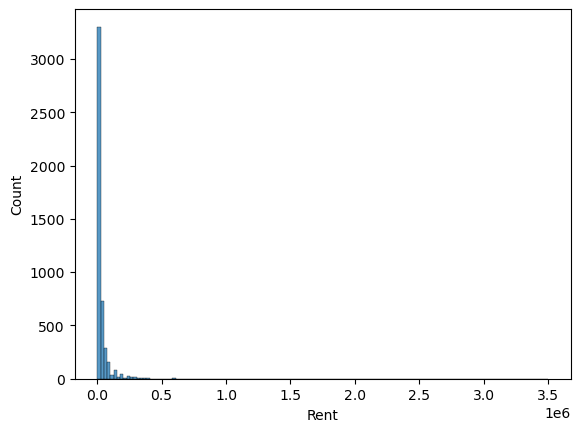

In [9]:
sns.histplot(x='Rent', data = df5)
plt.show()

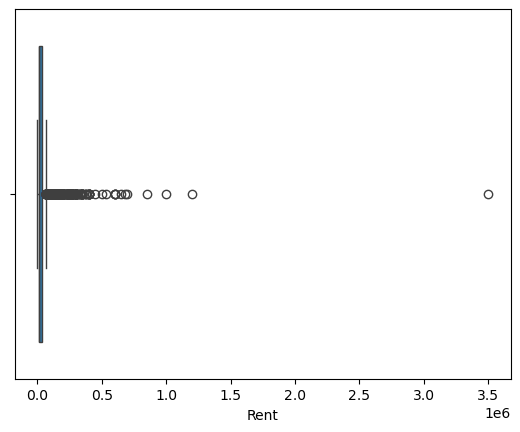

In [10]:
sns.boxplot(x='Rent', data = df5)
plt.show()

In [11]:
df5.describe().round(2)

,BHK,Rent,Size,Bathroom
count,4746.00,4746.00,4746.00,4746.00
mean,2.08,34993.45,967.49,1.97
std,0.83,78106.41,634.20,0.88
min,1.00,1200.00,10.00,1.00
25%,2.00,10000.00,550.00,1.00
50%,2.00,16000.00,850.00,2.00
75%,3.00,33000.00,1200.00,2.00
max,6.00,3500000.00,8000.00,10.00


In [12]:
df5 = df5[df5['Point of Contact'] != 'Contact Builder'].copy()

In [13]:
df5['Point of Contact'].value_counts()

Point of Contact
Contact Owner    3216
Contact Agent    1529
Name: count, dtype: int64

In [14]:
df5.drop(columns = ['Posted On', 'Area Locality', 'Floor'], axis = 1, inplace = True)
df5

,BHK,Rent,Size,Area Type,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2,10000,1100,Super Area,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2,20000,800,Super Area,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2,17000,1000,Super Area,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2,10000,800,Super Area,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2,7500,850,Carpet Area,Kolkata,Unfurnished,Bachelors,1,Contact Owner
...,...,...,...,...,...,...,...,...,...
4741,2,15000,1000,Carpet Area,Hyderabad,Semi-Furnished,Bachelors/Family,2,Contact Owner
4742,3,29000,2000,Super Area,Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Owner
4743,3,35000,1750,Carpet Area,Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Agent
4744,3,45000,1500,Carpet Area,Hyderabad,Semi-Furnished,Family,2,Contact Agent


In [15]:
x = df5.drop('Rent', axis = 1)
y = df5['Rent']

numerical_cols = x.select_dtypes(include = ['int64', 'float64']).columns 
categorical_cols = x.select_dtypes(include = ['object']).columns

In [16]:
numerical = Pipeline(steps = [
    ('num', StandardScaler())    
])

categorical = Pipeline(steps = [
    ('enc', OneHotEncoder(drop = 'first', sparse_output = False, handle_unknown = 'ignore'))
])
preprocessed = ColumnTransformer(transformers = [
    ('no', numerical, numerical_cols),
    ('cat', categorical, categorical_cols)
], verbose_feature_names_out = False, remainder = 'passthrough')

preprocessed.set_output(transform = 'pandas')

x_train, x_test, y_train, y_test = train_test_split(x, y, random_state = 43, test_size = 0.2)

x_train_pre = preprocessed.fit_transform(x_train)
x_test_pre = preprocessed.transform(x_test)

In [17]:
x_train_pre

,BHK,Size,Bathroom,Area Type_Carpet Area,Area Type_Super Area,City_Chennai,City_Delhi,City_Hyderabad,City_Kolkata,City_Mumbai,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,Tenant Preferred_Bachelors/Family,Tenant Preferred_Family,Point of Contact_Contact Owner
342,-0.094663,-0.418592,-1.077444,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2415,-0.094663,-0.540397,-1.077444,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0
1547,-0.094663,0.214160,0.048961,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0
2430,-0.094663,-0.576780,0.048961,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0
3743,1.111184,0.372348,0.048961,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307,1.111184,0.372348,0.048961,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
2064,1.111184,0.688724,1.175367,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2325,-1.300511,-1.367720,0.048961,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
2303,-0.094663,0.372348,0.048961,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0


In [18]:
modell = [('XGB Regressor', XGBRegressor(random_state = 43)),
         ('CatBoost Regressor', CatBoostRegressor(random_state = 43, verbose = 0)),
         ('Random Forest Regressor', RandomForestRegressor(random_state = 43)),
         ('Decision Tree', DecisionTreeRegressor(random_state = 43))]

In [19]:
scorez = {}


for cel, cels in modell:
    model = TransformedTargetRegressor(
        regressor = Pipeline([('prep', preprocessed),
                             ('models', cels)]),
        func = np.log1p,
        inverse_func = np.expm1
    )
    score = cross_val_score(model, x_train, y_train, cv = 5, scoring = 'neg_mean_absolute_error')
    scorez[cel] = -score
    

scorez_df = pd.DataFrame(scorez)
    

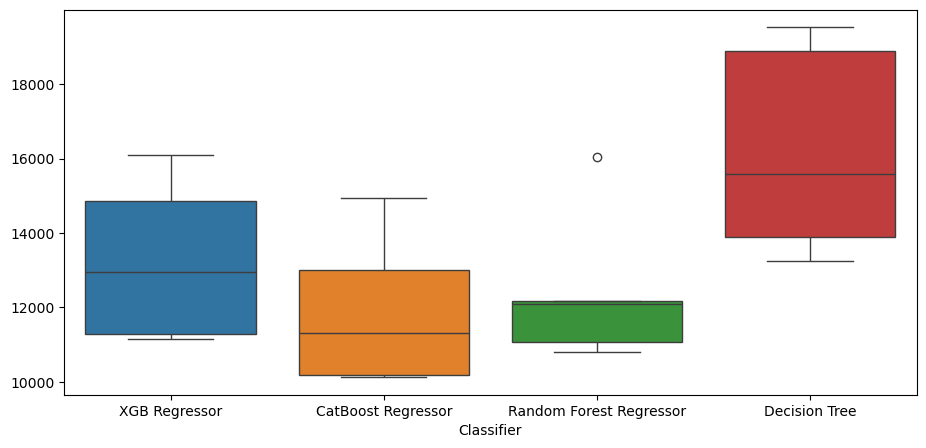

In [20]:
fig, ax = plt.subplots(figsize = (11, 5))
sns.boxplot(scorez_df)
plt.xlabel('Classifier', fontsize = (10))
plt.show()

In [21]:
print('Model performance std', scorez_df.std())

Model performance std XGB Regressor              2177.121352
CatBoost Regressor         2049.343514
Random Forest Regressor    2106.372493
Decision Tree              2866.414944
dtype: float64


In [22]:
dummy = DummyRegressor(strategy = 'median').fit(x_train_pre, y_train)
mae = mean_absolute_error(y_test, dummy.predict(x_test_pre))
print('Baseline MAE', mae)

Baseline MAE 26815.511064278187


In [23]:
cat = TransformedTargetRegressor(
    regressor = Pipeline([('pipe', preprocessed),
    ('cats', CatBoostRegressor(random_state = 43, verbose = 0))]),
    func = np.log1p,
    inverse_func = np.expm1)


cat.fit(x_train, y_train)

y_pred = cat.predict(x_test)

In [24]:
results = pd.DataFrame({'actual':y_test.values, 'predicted':y_pred.round(0)})
results['erro'] = results['predicted'] - results['actual']
results

,actual,predicted,erro
0,4000,10562.0,6562.0
1,7500,7597.0,97.0
2,13000,11604.0,-1396.0
3,20000,13472.0,-6528.0
4,7000,7064.0,64.0
...,...,...,...
944,32000,29835.0,-2165.0
945,28000,26038.0,-1962.0
946,5500,6372.0,872.0
947,7500,7287.0,-213.0


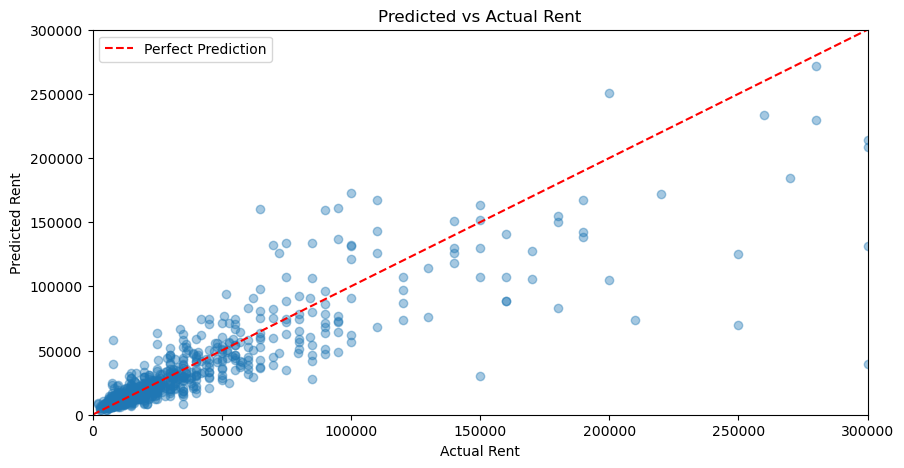

In [25]:
fig, ax = plt.subplots(figsize = (10, 5))
plt.scatter(y_test, y_pred, alpha = 0.4)
lims = [0, y_test.quantile(0.99)]
plt.plot(lims, lims, 'r--', label = 'Perfect Prediction')
ax.set(xlim = lims, ylim = lims, xlabel = 'Actual Rent', ylabel = 'Predicted Rent', title = 'Predicted vs Actual Rent')
plt.legend()
plt.show()
